# Supplementary Figure S3 — plotting


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path(os.environ.get("MITOXY_PROJECT_ROOT","/scratch/ar58064/mitoxy")).resolve()
BLUE="#087EBD"; ORANGE="#E36A00"; TEAL="#00A67E"; PURPLE="#8053A6"
DARK="#202832"; MID="#667386"; GRID="#DDE3E9"; BAND="#F2F5F8"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelcolor":DARK,
 "xtick.color":MID,"ytick.color":DARK,"axes.edgecolor":"#AEB8C4","axes.spines.top":False,
 "axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})

def panel_letter(ax,letter):
    ax.text(-.14,1.08,letter,transform=ax.transAxes,fontsize=21,fontweight="bold",color=DARK,va="top")

def band_rows(ax,n):
    for i in range(n):
        if i%2==0: ax.axhspan(i-.5,i+.5,color=BAND,zorder=0)

def p_text(p): return "P < 1e-4" if p < 1e-4 else f"P = {p:.3f}"

def stat_box(ax,x,y,text,color):
    ax.text(x,y,text,transform=ax.transAxes,ha="left",va="center",fontsize=8.3,fontweight="bold",color=color,
            bbox=dict(boxstyle="round,pad=.26",facecolor="white",edgecolor=color,alpha=.95,linewidth=1))

def save_all(fig,stem,folder):
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ["png","pdf","svg"]:
        fig.savefig(folder/f"{stem}.{ext}",dpi=320 if ext=="png" else None,bbox_inches="tight")

DATA_DIR=PROJECT_ROOT/"data"/"processed"/"supplementary_figure_s3"; FIGURE_DIR=PROJECT_ROOT/"figures"/"supplementary_figure_s3"
a=pd.read_csv(DATA_DIR/"panel_a_pc1_equal4.csv"); b=pd.read_csv(DATA_DIR/"panel_b_emtab_components.csv"); c=pd.read_csv(DATA_DIR/"panel_c_myeloid_components.csv")
d=pd.read_csv(DATA_DIR/"panel_d_tracerx_architectures.csv"); e=pd.read_csv(DATA_DIR/"panel_e_tcga_joint.csv")


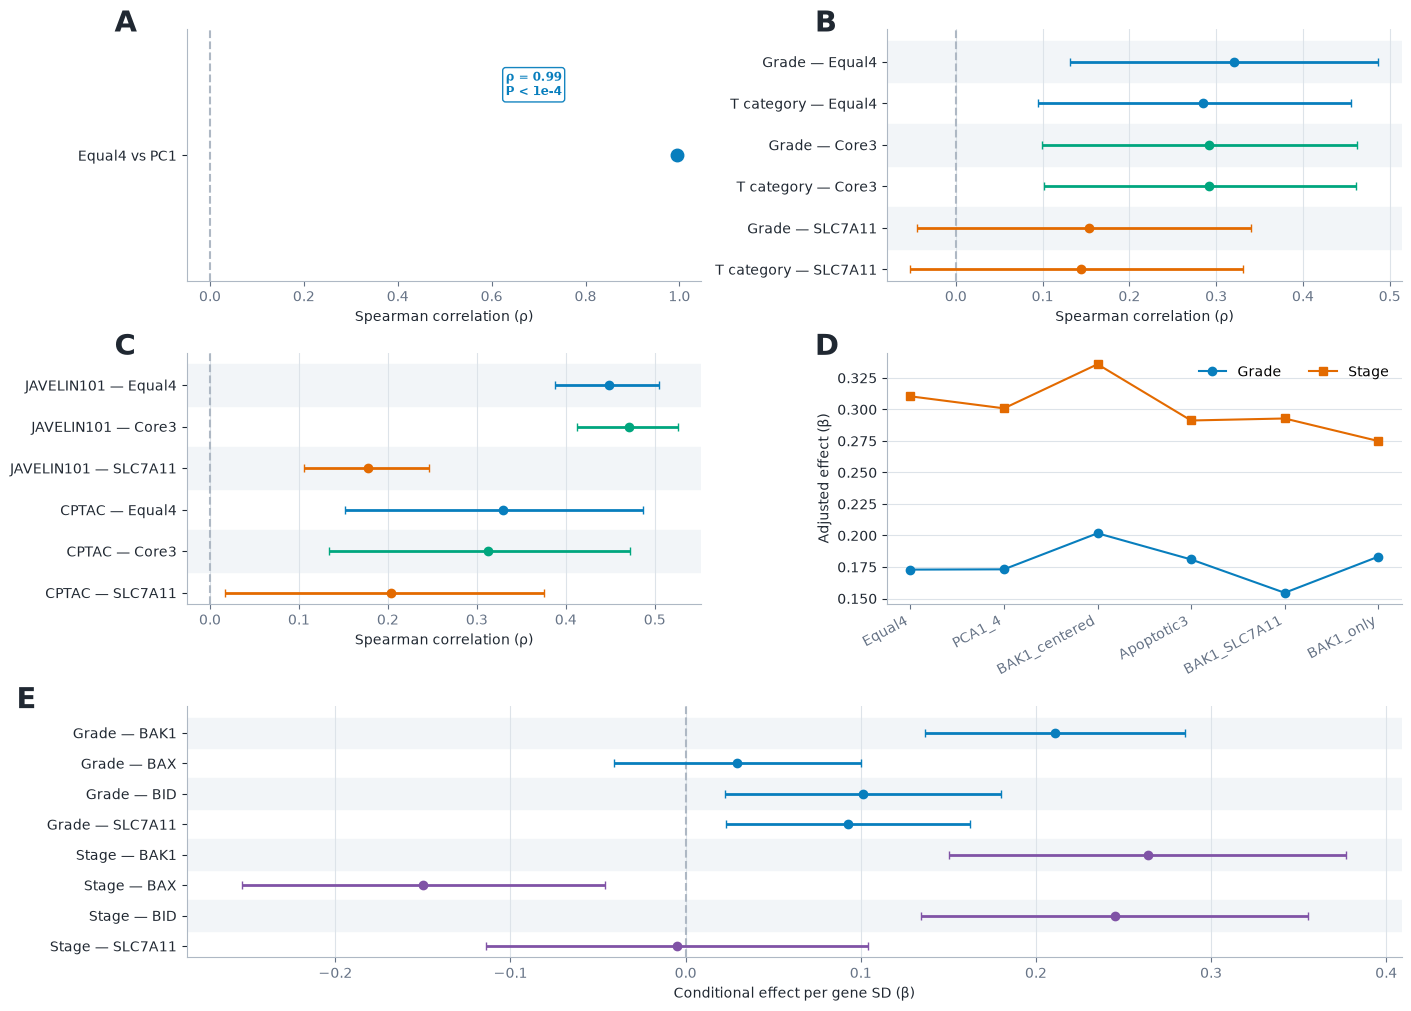

In [3]:
fig=plt.figure(figsize=(14,10),constrained_layout=True); gs=fig.add_gridspec(3,2)
axes=[fig.add_subplot(gs[0,0]),fig.add_subplot(gs[0,1]),fig.add_subplot(gs[1,0]),fig.add_subplot(gs[1,1]),fig.add_subplot(gs[2,:])]
# A
ax=axes[0]; row=a.iloc[0]; ax.errorbar(row.rho,0,xerr=[[row.rho-row.ci_low],[row.ci_high-row.rho]],fmt="o",ms=9,color=BLUE,capsize=4,lw=2); ax.axvline(0,color="#AEB8C4",ls="--")
ax.set_yticks([0],["Equal4 vs PC1"]); ax.set_xlabel("Spearman correlation (ρ)"); stat_box(ax,.62,.78,f"ρ = {row.rho:.2f}\n{p_text(row.p_value)}",BLUE); panel_letter(ax,"A")
# B/C
for ax,table,title,letter in [(axes[1],b,"","B"),(axes[2],c,"","C")]:
    labels=(table.endpoint+" — "+table.score) if letter=="B" else (table.cohort+" — "+table.score); y=np.arange(len(table)); band_rows(ax,len(table)); ax.axvline(0,color="#AEB8C4",ls="--")
    for i,row in table.iterrows():
        color={"Equal4":BLUE,"Core3":TEAL,"SLC7A11":ORANGE}[row.score]; ax.errorbar(row.rho,i,xerr=[[row.rho-row.ci_low],[row.ci_high-row.rho]],fmt="o",color=color,capsize=3,lw=2)
    ax.set_yticks(y,labels); ax.invert_yaxis(); ax.set_xlabel("Spearman correlation (ρ)"); ax.grid(axis="x",color=GRID); ax.set_title(title,loc="left",fontweight="bold"); panel_letter(ax,letter)
# D
ax=axes[3]; x=np.arange(len(d)); ax.plot(x,d.grade_effect,"o-",color=BLUE,label="Grade"); ax.plot(x,d.stage_effect,"s-",color=ORANGE,label="Stage"); ax.set_xticks(x,d.score,rotation=28,ha="right"); ax.set_ylabel("Adjusted effect (β)"); ax.legend(frameon=False,ncol=2); ax.grid(axis="y",color=GRID); ax.set_title("",loc="left",fontweight="bold"); panel_letter(ax,"D")
# E
ax=axes[4]; labels=e.endpoint+" — "+e.gene; y=np.arange(len(e)); band_rows(ax,len(e)); ax.axvline(0,color="#AEB8C4",ls="--")
for i,row in e.iterrows():
    color=BLUE if row.endpoint=="Grade" else PURPLE; ax.errorbar(row.effect,i,xerr=[[row.effect-row.ci_low],[row.ci_high-row.effect]],fmt="o",color=color,capsize=3,lw=2)
ax.set_yticks(y,labels); ax.invert_yaxis(); ax.set_xlabel("Conditional effect per gene SD (β)"); ax.grid(axis="x",color=GRID); ax.set_title("",loc="left",fontweight="bold"); panel_letter(ax,"E")
save_all(fig,"Supplementary_Figure_S3",FIGURE_DIR); plt.show()
